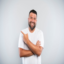

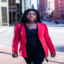

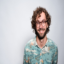

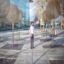

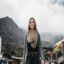

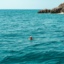

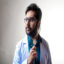

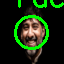

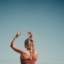

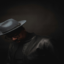

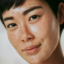

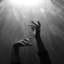

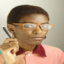

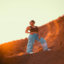

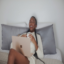

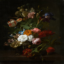

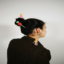

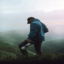

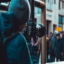

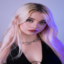

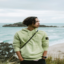

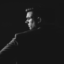

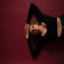

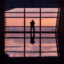

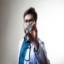

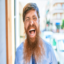

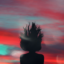

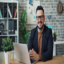

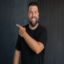

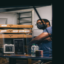

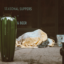

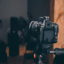

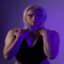

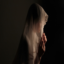

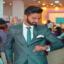

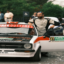

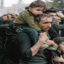

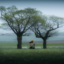

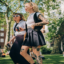

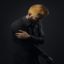

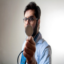

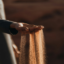

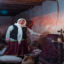

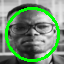

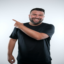

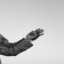

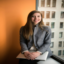

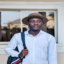

In [ ]:
import os
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, datasets
from PIL import Image
import zipfile
import numpy as np
from google.colab.patches import cv2_imshow

# CNN Model Definition
class FaceDetectionModel(nn.Module):
    def __init__(self):
        super(FaceDetectionModel, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 1)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 64 * 16 * 16)
        x = torch.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return x

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

zip_path = "1802zipp.zip"
extract_folder = "images/extracted_images"
if not os.path.exists(extract_folder):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_folder)

dataset = datasets.ImageFolder(root=extract_folder, transform=transform)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model = FaceDetectionModel().to(device := torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(10):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

torch.save(model.state_dict(), 'face_model.pth')

model.eval()
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
for images, _ in test_loader:
    images = images.to(device)
    with torch.no_grad():
        outputs = model(images)
        for i in range(len(images)):
            img = images[i].permute(1, 2, 0).cpu().numpy()
            img = cv2.cvtColor((img * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)
            for (x, y, w, h) in faces:
                center = (x + w // 2, y + h // 2)
                radius = max(w, h) // 2
                cv2.circle(img, center, radius, (0, 255, 0), 2)
                cv2.putText(img, 'Face', (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
            cv2_imshow(img)


